# 03 · Optimización de hiperparámetros para MLP A y MLP B

**Objetivo:** encontrar configuraciones de MLP con presupuesto de búsqueda **idéntico** para A (sin entrenamiento) y B (con entrenamiento), usando sólo validación.

**Protocolo:**
1. Análisis de sensibilidad de `typical` y `max` (Ridge B, y luego MLP B).
2. Búsqueda aleatoria en dos etapas:
   - **Etapa 1:** 150 configuraciones muestreadas del espacio completo, con una semilla y early stopping.
   - **Etapa 2:** las 10 mejores de cada variante, re-entrenadas con 5 semillas nuevas.
3. Comparación final en validación. El test permanece reservado y no se usa aquí.

Las particiones, el preprocesamiento y el código de entrenamiento vienen de `src/common.py`, el mismo que usa el notebook 02.

## 0. Configuración

In [1]:
import itertools, math, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "processed" / "df_long.parquet").exists():
            return p
    raise FileNotFoundError("No se encontró data/processed/df_long.parquet")

ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
from common import (SEED, DEVICE, TARGET, FEATS_A, FEATS_B, ENTRENO,
                    load_data, split_by_runner, prepare, train_mlp, predict,
                    metrics, set_seed)

RESULTS = ROOT / "resultados"
RESULTS.mkdir(exist_ok=True)

N_CONFIG = 150                        # configuraciones de la etapa 1
TOP_K = 10                            # configuraciones que pasan a la etapa 2
SEED_SEARCH = 0                       # semilla de la etapa 1
SEEDS_FINAL = [100, 101, 102, 103, 104]   # semillas nuevas para la etapa 2
ES = {"patience": 15, "max_epochs": 200}  # early stopping (igual para A y B)
HP_ORIG = dict(hidden=(64, 32), dropout=0.2, lr=1e-3, weight_decay=1e-4,
               batch_size=64, optimizer="Adam", epochs=80)

print(f"Raíz: {ROOT}\nDevice: {DEVICE}")

Raíz: /Users/mirandaurbansolano/GitHub/tc3009C-deep-learning-project
Device: cpu


## 1. Carga, partición y escalado

In [2]:
df = load_data(ROOT)
train, val, test = split_by_runner(df)
y_tr, y_va = train[TARGET].values, val[TARGET].values
# test se carga sólo para fijar la partición; no se usa en este notebook.

XS = {"A": prepare(train, val, FEATS_A), "B": prepare(train, val, FEATS_B)}
print(f"train={len(train)} filas, val={len(val)} filas (test reservado).")

train=3597 filas, val=778 filas (test reservado).


## 2. Análisis de sensibilidad: `typical` y `max`

Correlación 0.91 entre ambas. Antes de optimizar, comparo tres versiones de B:
- **B completo:** con `typical` y `max`.
- **B sin `typical`**
- **B sin `max`**

No elimino variables por su correlación. Sólo cambio la decisión si la pérdida de una de ellas es nula o la otra no aporta. 

Primero con Ridge B, luego con MLP B usando la configuración original (80 épocas, sin early stopping) y 5 semillas.

In [3]:
from sklearn.linear_model import Ridge

SENS = {
    "B completo": FEATS_B,
    "B sin typical": [f for f in FEATS_B if f != "typical"],
    "B sin max": [f for f in FEATS_B if f != "max"],
}

ridge_rows = []
for name, feats in SENS.items():
    Xtr, Xva = prepare(train, val, feats)
    r = Ridge(alpha=1.0).fit(Xtr, y_tr)
    ridge_rows.append({"modelo": f"Ridge ({name})", **metrics(y_va, r.predict(Xva))})
sens_ridge = pd.DataFrame(ridge_rows).round(3)
display(sens_ridge)

,modelo,RMSE,MAE,R2
0,Ridge (B completo),1.460,1.145,0.717
1,Ridge (B sin typical),1.484,1.171,0.708
2,Ridge (B sin max),1.471,1.154,0.713


In [4]:
mlp_sens_rows = []
for name, feats in SENS.items():
    Xtr, Xva = prepare(train, val, feats)
    for seed in [0, 1, 2, 3, 4]:
        m, _, _ = train_mlp(Xtr, y_tr, Xva, y_va, seed=seed, **HP_ORIG)
        mlp_sens_rows.append({"modelo": f"MLP ({name})", "semilla": seed,
                              **metrics(y_va, predict(m, Xva))})
sens_mlp_raw = pd.DataFrame(mlp_sens_rows)
sens_mlp = (sens_mlp_raw.groupby("modelo")[["RMSE", "MAE", "R2"]]
            .agg(["mean", "std"]).round(3))
display(sens_mlp)

RMSE           MAE            R2       
                      mean    std   mean    std   mean    std
modelo                                                       
MLP (B completo)     1.519  0.018  1.182  0.021  0.693  0.007
MLP (B sin max)      1.524  0.015  1.187  0.015  0.692  0.006
MLP (B sin typical)  1.543  0.012  1.209  0.014  0.684  0.005

### Decisión de sensibilidad

Lectura: si quitar una variable empeora poco, la otra la sustituye en parte. Si quitarla no cambia nada, la variable es redundante para la predicción. La decisión final está en la sección de conclusiones.

## 3. Diseño de la búsqueda

**Espacio completo:** 7 arquitecturas × 4 learning rates × 4 dropouts × 3 weight decays × 3 batch sizes × 2 optimizadores = **2016 configuraciones**.

**Por qué búsqueda aleatoria y no grid:** un grid completo serían 2016 × 2 variantes × 5 semillas ≈ 20 mil entrenamientos. Con early stopping cada uno tarda unos 6 s en CPU, así que el grid completo costaría más de 30 horas, sin contar reintentos.

**Cuántas configuraciones:** muestreo sin reemplazo de 150 configuraciones (7.4% del espacio). Si el 2% superior del espacio (40 configuraciones) tiene al menos una configuración buena, la probabilidad de muestrear al menos una es:

$$P = 1 - \binom{2016-40}{150} / \binom{2016}{150} \approx 0.96$$

**Mismo presupuesto para A y B:** las mismas 150 configuraciones se entrenan en ambas variantes, con la misma semilla y el mismo early stopping.

**Etapa 2:** las 10 mejores de cada variante (según validación en la semilla 0) se repiten con 5 semillas nuevas (100–104). Así se evita elegir una configuración por una sola ejecución afortunada.

**Early stopping:** paciencia de 15 épocas sobre la pérdida de validación, máximo 200 épocas, con restauración de los pesos de la mejor época. Igual para A y B.

**Criterio de selección:** RMSE medio en validación en la etapa 2.

**Limitación:** la selección usa validación, así que el RMSE de validación de la mejor configuración está optimista. El test queda para la evaluación final.

In [5]:
SPACE = {
    "hidden": [(32,), (64,), (128,), (64, 32), (128, 64), (128, 64, 32), (256, 128)],
    "lr": [1e-4, 5e-4, 1e-3, 3e-3],
    "dropout": [0.0, 0.1, 0.2, 0.3],
    "weight_decay": [0.0, 1e-4, 1e-3],
    "batch_size": [32, 64, 128],
    "optimizer": ["Adam", "AdamW"],
}
ALL = list(itertools.product(*SPACE.values()))
assert len(ALL) == 2016

rng = np.random.default_rng(SEED)
idx = rng.choice(len(ALL), size=N_CONFIG, replace=False)
CONFIGS = [{"config_id": int(i), **dict(zip(SPACE.keys(), ALL[i]))} for i in idx]

p_top40 = 1 - math.comb(len(ALL) - 40, N_CONFIG) / math.comb(len(ALL), N_CONFIG)
print(f"Espacio: {len(ALL)} configuraciones. Muestreadas: {N_CONFIG} ({N_CONFIG/len(ALL):.1%}).")
print(f"P(al menos una del 2% superior) = {p_top40:.3f}")
print(f"Entrenamientos previstos: etapa 1 = {2*N_CONFIG}; etapa 2 = {2*TOP_K*len(SEEDS_FINAL)}; "
      f"sensibilidad MLP = 15; reproducción original = {2*len(SEEDS_FINAL)}.")

Espacio: 2016 configuraciones. Muestreadas: 150 (7.4%).
P(al menos una del 2% superior) = 0.956
Entrenamientos previstos: etapa 1 = 300; etapa 2 = 100; sensibilidad MLP = 15; reproducción original = 10.


## 4. Etapa 1: búsqueda con una semilla

In [6]:
def cfg_kwargs(cfg):
    return {k: cfg[k] for k in ["hidden", "lr", "dropout", "weight_decay",
                                "batch_size", "optimizer"]}

def run(variant, cfg, seed):
    Xtr, Xva = XS[variant]
    t0 = time.time()
    m, hist, best_ep = train_mlp(Xtr, y_tr, Xva, y_va, seed=seed,
                                 early_stopping=ES, **cfg_kwargs(cfg))
    row = {"variante": variant, "config_id": cfg["config_id"], "semilla": seed,
           **{k: (str(v) if k == "hidden" else v) for k, v in cfg_kwargs(cfg).items()},
           "mejor_epoca": best_ep, "epocas_ejecutadas": len(hist["val"]),
           **metrics(y_va, predict(m, Xva)), "segundos": round(time.time() - t0, 1)}
    return row, hist

stage1, stage1_hist = [], {}
t_start = time.time()
for variant in ["A", "B"]:
    for n, cfg in enumerate(CONFIGS, 1):
        row, hist = run(variant, cfg, SEED_SEARCH)
        stage1.append(row)
        stage1_hist[(variant, cfg["config_id"])] = hist
        if n % 25 == 0:
            print(f"variante {variant}: {n}/{N_CONFIG}  ({(time.time()-t_start)/60:.1f} min)")

stage1_df = pd.DataFrame(stage1)
stage1_df.to_csv(RESULTS / "03_busqueda_etapa1.csv", index=False)
print("Etapa 1 guardada. Filas:", len(stage1_df))

variante A: 25/150  (0.8 min)
variante A: 50/150  (1.8 min)
variante A: 75/150  (2.8 min)
variante A: 100/150  (3.9 min)
variante A: 125/150  (4.8 min)
variante A: 150/150  (5.8 min)
variante B: 25/150  (6.8 min)
variante B: 50/150  (7.8 min)
variante B: 75/150  (9.0 min)
variante B: 100/150  (10.3 min)
variante B: 125/150  (11.4 min)
variante B: 150/150  (12.5 min)
Etapa 1 guardada. Filas: 300


In [7]:
s1 = stage1_df.groupby("variante")["RMSE"].describe().round(3)
display(s1)
display(stage1_df.sort_values(["variante", "RMSE"]).groupby("variante").head(5)
        [["variante", "config_id", "hidden", "lr", "dropout", "weight_decay",
          "batch_size", "optimizer", "RMSE", "mejor_epoca"]].round(3))

,count,mean,std,min,25%,50%,75%,max
variante,,,,,,,,
A,150.0,1.944,0.087,1.890,1.910,1.918,1.935,2.370
B,150.0,1.521,0.098,1.444,1.476,1.495,1.516,1.994


,variante,config_id,hidden,lr,dropout,weight_decay,batch_size,optimizer,RMSE,mejor_epoca
43,A,840,"(128,)",0.003,0.2,0.001,32,Adam,1.890,66
2,A,1097,"(64, 32)",0.003,0.0,0.001,128,AdamW,1.896,57
140,A,547,"(64,)",0.003,0.2,0.000,32,AdamW,1.897,43
92,A,1956,"(256, 128)",0.003,0.0,0.001,32,Adam,1.899,13
144,A,565,"(64,)",0.003,0.3,0.000,32,AdamW,1.899,43
230,B,252,"(32,)",0.003,0.2,0.000,32,Adam,1.444,71
238,B,1717,"(128, 64, 32)",0.003,0.3,0.000,32,AdamW,1.447,25
186,B,277,"(32,)",0.003,0.3,0.000,32,AdamW,1.450,56
172,B,1855,"(256, 128)",0.000,0.3,0.000,32,AdamW,1.452,58
295,B,1867,"(256, 128)",0.000,0.3,0.001,32,AdamW,1.453,58


## 5. Etapa 2: estabilidad con 5 semillas nuevas

Se usan las 10 mejores configuraciones de cada variante según la etapa 1 para entrenar con las semillas 100–104. El criterio de selección es el RMSE medio sobre las 5 semillas.

In [7]:
stage2 = []
for variant in ["A", "B"]:
    top = (stage1_df[stage1_df["variante"] == variant]
           .nsmallest(TOP_K, "RMSE")["config_id"].tolist())
    for cid in top:
        cfg = next(c for c in CONFIGS if c["config_id"] == cid)
        for seed in SEEDS_FINAL:
            row, hist = run(variant, cfg, seed)
            stage2.append(row)
            stage1_hist[("s2", variant, cid, seed)] = hist
    print(f"variante {variant}: 10 configuraciones × 5 semillas listas")

stage2_df = pd.DataFrame(stage2)
stage2_df.to_csv(RESULTS / "03_busqueda_etapa2.csv", index=False)

stage2_sum = (stage2_df.groupby(["variante", "config_id"])
              .agg(RMSE_medio=("RMSE", "mean"), RMSE_sd=("RMSE", "std"),
                   MAE_medio=("MAE", "mean"), R2_medio=("R2", "mean"),
                   mejor_epoca_media=("mejor_epoca", "mean"))
              .reset_index()
              .sort_values(["variante", "RMSE_medio"]))
stage2_sum.round(3).to_csv(RESULTS / "03_busqueda_etapa2_resumen.csv", index=False)
display(stage2_sum.round(3))

variante A: 10 configuraciones × 5 semillas listas
variante B: 10 configuraciones × 5 semillas listas


,variante,config_id,RMSE_medio,RMSE_sd,MAE_medio,R2_medio,mejor_epoca_media
2,A,840,1.888,0.013,1.511,0.527,46.6
4,A,1430,1.888,0.015,1.509,0.527,48.4
3,A,1097,1.903,0.012,1.524,0.519,42.2
5,A,1832,1.903,0.004,1.522,0.519,41.6
9,A,1996,1.905,0.009,1.522,0.518,26.6
6,A,1867,1.907,0.013,1.529,0.517,32.4
0,A,547,1.911,0.011,1.532,0.515,44.4
1,A,565,1.912,0.008,1.535,0.515,33.6
8,A,1957,1.919,0.009,1.535,0.511,12.4
7,A,1956,1.919,0.008,1.535,0.511,12.4


## 6. Mejores configuraciones y comparación final

In [8]:
best = {v: stage2_sum[stage2_sum["variante"] == v].iloc[0] for v in ["A", "B"]}
best_cfg = {v: next(c for c in CONFIGS if c["config_id"] == int(best[v]["config_id"]))
            for v in ["A", "B"]}
for v in ["A", "B"]:
    print(f"Mejor MLP {v}: config {int(best[v]['config_id'])} → {cfg_kwargs(best_cfg[v])}")

# Reproducción de la configuración original con early stopping y semillas 100–104,
# para comparar en el mismo protocolo que las configuraciones optimizadas.
orig_es = {"A": [], "B": []}
for v in ["A", "B"]:
    Xtr, Xva = XS[v]
    for seed in SEEDS_FINAL:
        m, hist, be = train_mlp(Xtr, y_tr, Xva, y_va, seed=seed, early_stopping=ES, **HP_ORIG)
        orig_es[v].append({"variante": v, "semilla": seed, "mejor_epoca": be,
                           **metrics(y_va, predict(m, Xva))})
orig_es_df = pd.DataFrame([r for v in orig_es for r in orig_es[v]])

# Originales de 02 (80 épocas fijas, semillas 0–4), leídos del CSV ya generado
orig02 = pd.read_csv(RESULTS / "02_ablacion_mlp_por_semilla.csv")
ridge02 = pd.read_csv(RESULTS / "02_ablacion_lineal.csv")
print("Originales de 02 y configuraciones de Ridge cargadas.")

Mejor MLP A: config 840 → {'hidden': (128,), 'lr': 0.003, 'dropout': 0.2, 'weight_decay': 0.001, 'batch_size': 32, 'optimizer': 'Adam'}
Mejor MLP B: config 1633 → {'hidden': (128, 64, 32), 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.001, 'batch_size': 32, 'optimizer': 'AdamW'}
Originales de 02 y configuraciones de Ridge cargadas.


In [9]:
def summarize(series_rmse, series_mae, series_r2):
    return {
        "RMSE": f"{series_rmse.mean():.3f} ± {series_rmse.std():.3f}",
        "MAE": f"{series_mae.mean():.3f} ± {series_mae.std():.3f}",
        "R²": f"{series_r2.mean():.3f} ± {series_r2.std():.3f}",
        "RMSE_min": round(series_rmse.min(), 3),
        "RMSE_max": round(series_rmse.max(), 3),
    }

rows = []

for v in ["A", "B"]:
    s = stage2_df[(stage2_df["variante"] == v) &
                  (stage2_df["config_id"] == int(best[v]["config_id"]))]
    rows.append({"modelo": f"Mejor MLP {v} (optimizada)", "protocolo": "ES, semillas 100–104",
                 **summarize(s["RMSE"], s["MAE"], s["R2"])})

for v in ["A", "B"]:
    s = orig_es_df[orig_es_df["variante"] == v]
    rows.append({"modelo": f"MLP {v} original", "protocolo": "ES, semillas 100–104",
                 **summarize(s["RMSE"], s["MAE"], s["R2"])})

for v, name in [("A", "MLP A original (02)"), ("B", "MLP B original (02)")]:
    s = orig02[orig02["modelo"].str.contains(f"MLP {v}")]
    rows.append({"modelo": name, "protocolo": "80 épocas, semillas 0–4",
                 **summarize(s["RMSE"], s["MAE"], s["R2"])})

for v in ["A", "B"]:
    r = ridge02[ridge02["modelo"] == f"Ridge {v}"].iloc[0]
    rows.append({"modelo": f"Ridge {v}", "protocolo": "determinista",
                 "RMSE": f"{r.RMSE:.3f}", "MAE": f"{r.MAE:.3f}", "R²": f"{r.R2:.3f}",
                 "RMSE_min": round(r.RMSE, 3), "RMSE_max": round(r.RMSE, 3)})

comp = pd.DataFrame(rows)
comp.to_csv(RESULTS / "03_comparacion_final_validacion.csv", index=False)
display(comp)

,modelo,protocolo,RMSE,MAE,R²,RMSE_min,RMSE_max
0,Mejor MLP A (optimizada),"ES, semillas 100–104",1.888 ± 0.013,1.511 ± 0.013,0.527 ± 0.007,1.874,1.902
1,Mejor MLP B (optimizada),"ES, semillas 100–104",1.448 ± 0.006,1.131 ± 0.007,0.722 ± 0.002,1.439,1.453
2,MLP A original,"ES, semillas 100–104",1.919 ± 0.007,1.535 ± 0.006,0.511 ± 0.004,1.907,1.926
3,MLP B original,"ES, semillas 100–104",1.492 ± 0.019,1.161 ± 0.017,0.705 ± 0.008,1.466,1.516
4,MLP A original (02),"80 épocas, semillas 0–4",1.957 ± 0.016,1.554 ± 0.010,0.492 ± 0.008,1.941,1.977
5,MLP B original (02),"80 épocas, semillas 0–4",1.519 ± 0.018,1.182 ± 0.021,0.693 ± 0.007,1.509,1.552
6,Ridge A,determinista,1.946,1.573,0.497,1.946,1.946
7,Ridge B,determinista,1.460,1.145,0.717,1.460,1.460


### 6.1 Preguntas del objetivo

In [10]:
# 1. ¿La optimización mejora cada MLP? (mismo protocolo: ES, semillas 100–104)
for v in ["A", "B"]:
    o = orig_es_df[orig_es_df["variante"] == v].set_index("semilla")["RMSE"]
    b = stage2_df[(stage2_df["variante"] == v) &
                  (stage2_df["config_id"] == int(best[v]["config_id"]))].set_index("semilla")["RMSE"]
    d = (b - o)
    print(f"1. MLP {v}: RMSE optimizada − original = {d.mean():+.3f} km/h "
          f"(mejor en {int((d<0).sum())}/5 semillas)")

# 2. ¿MLP B sigue superando a MLP A? (pareado por semilla, con las mejores configs)
bA = stage2_df[(stage2_df["variante"]=="A") & (stage2_df["config_id"]==int(best["A"]["config_id"]))].set_index("semilla")["RMSE"]
bB = stage2_df[(stage2_df["variante"]=="B") & (stage2_df["config_id"]==int(best["B"]["config_id"]))].set_index("semilla")["RMSE"]
dAB = bB - bA
print(f"2. B − A (optimizadas): {dAB.mean():+.3f} km/h; B mejor en {int((dAB<0).sum())}/5 semillas")

# 3. ¿Alguna MLP supera a Ridge B (RMSE 1.460)?
ridgeB = float(ridge02[ridge02["modelo"]=="Ridge B"]["RMSE"].iloc[0])
for v in ["A", "B"]:
    m_rmse = stage2_sum[stage2_sum["variante"]==v]["RMSE_medio"].min()
    print(f"3. Mejor MLP {v} (media 5 semillas) = {m_rmse:.3f}  vs Ridge B = {ridgeB:.3f}  →  "
          f"{'supera' if m_rmse < ridgeB else 'no supera'} a Ridge B")

# 4. ¿La mejora es consistente o depende de una configuración?
for v in ["A", "B"]:
    top = stage2_sum[stage2_sum["variante"]==v]
    n_mejor_orig = int((top["RMSE_medio"] < orig_es_df[orig_es_df["variante"]==v]["RMSE"].mean()).sum())
    n_sup_ridge = int((top["RMSE_medio"] < ridgeB).sum())
    print(f"4. MLP {v}: {n_mejor_orig}/10 de las top-10 superan la original (ES); "
          f"{n_sup_ridge}/10 superan a Ridge B")

1. MLP A: RMSE optimizada − original = -0.031 km/h (mejor en 5/5 semillas)
1. MLP B: RMSE optimizada − original = -0.044 km/h (mejor en 5/5 semillas)
2. B − A (optimizadas): -0.440 km/h; B mejor en 5/5 semillas
3. Mejor MLP A (media 5 semillas) = 1.888  vs Ridge B = 1.460  →  no supera a Ridge B
3. Mejor MLP B (media 5 semillas) = 1.448  vs Ridge B = 1.460  →  supera a Ridge B
4. MLP A: 9/10 de las top-10 superan la original (ES); 0/10 superan a Ridge B
4. MLP B: 10/10 de las top-10 superan la original (ES); 5/10 superan a Ridge B


## 7. Curvas de entrenamiento y validación

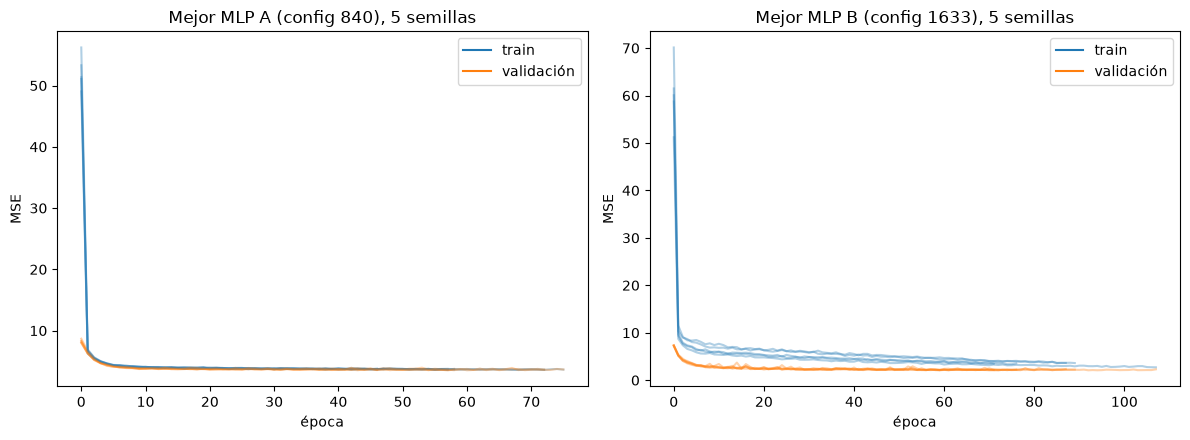

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
curve_rows = []
for ax, v in zip(axes, ["A", "B"]):
    cid = int(best[v]["config_id"])
    for seed in SEEDS_FINAL:
        h = stage1_hist.get(("s2", v, cid, seed))
        if h is None:
            continue
        ax.plot(h["train"], color="tab:blue", alpha=0.35)
        ax.plot(h["val"], color="tab:orange", alpha=0.35)
        for ep, (tr_l, va_l) in enumerate(zip(h["train"], h["val"])):
            curve_rows.append({"variante": v, "config_id": cid, "semilla": seed,
                               "epoca": ep, "train_mse": tr_l, "val_mse": va_l})
    ax.plot([], [], color="tab:blue", label="train")
    ax.plot([], [], color="tab:orange", label="validación")
    ax.set_title(f"Mejor MLP {v} (config {cid}), 5 semillas")
    ax.set_xlabel("época"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.show()

pd.DataFrame(curve_rows).to_csv(RESULTS / "03_curvas_mejores.csv", index=False)

## 8. Estabilidad entre semillas

In [12]:
stab = (stage2_df.groupby(["variante", "config_id"])
        .agg(RMSE_sd=("RMSE", "std"), RMSE_rango=("RMSE", lambda x: x.max() - x.min()))
        .round(4))
display(stab.loc[["A", "B"]].head(20))

RMSE_sd  RMSE_rango
variante config_id                     
A        547         0.0110      0.0284
         565         0.0078      0.0185
         840         0.0135      0.0279
         1097        0.0125      0.0297
         1430        0.0145      0.0363
         1832        0.0038      0.0087
         1867        0.0131      0.0352
         1956        0.0083      0.0205
         1957        0.0086      0.0195
         1996        0.0089      0.0225
B        252         0.0118      0.0294
         277         0.0099      0.0236
         1551        0.0202      0.0436
         1627        0.0087      0.0205
         1633        0.0058      0.0133
         1717        0.0145      0.0373
         1777        0.0103      0.0239
         1855        0.0058      0.0156
         1867        0.0041      0.0091
         1924        0.0072      0.0190

## 9. Notas de ejecución

In [13]:
print(f"Tiempo total de la etapa 1: {stage1_df['segundos'].sum()/60:.1f} min (sólo entrenamiento)")
print(f"Tiempo total de la etapa 2: {stage2_df['segundos'].sum()/60:.1f} min")
print(f"Dispositivo: {DEVICE}; semilla base: {SEED}")
print("Archivos en", RESULTS, ":")
for f in sorted(RESULTS.glob("03_*.csv")):
    print("  ", f.name)

Tiempo total de la etapa 1: 12.5 min (sólo entrenamiento)
Tiempo total de la etapa 2: 4.2 min
Dispositivo: cpu; semilla base: 42
Archivos en /Users/mirandaurbansolano/GitHub/tc3009C-deep-learning-project/resultados :
   03_busqueda_etapa1.csv
   03_busqueda_etapa2.csv
   03_busqueda_etapa2_resumen.csv
   03_comparacion_final_validacion.csv
   03_curvas_mejores.csv


## Conclusiones (validación)

**Sensibilidad de `typical` y `max`.** Ambas aportan algo. Quitar `typical` empeora Ridge B en 0.024 km/h y MLP B en 0.023. Quitar `max` empeora Ridge B en 0.011 y MLP B sólo en 0.004, dentro de la desviación entre semillas. `max` es casi redundante en la MLP, pero no se elimina por correlación. Se mantienen ambas.

**Optimización.** Con el mismo protocolo (early stopping, semillas 100–104), la búsqueda mejora poco respecto a la configuración original: MLP A −0.031 km/h y MLP B −0.044 km/h, mejorando en 5/5 semillas. Las 10 mejores de cada variante superan a la original, así que la mejora no depende de una configuración aislada.

**MLP B sigue superando a MLP A.** Con las mejores configuraciones, B − A = −0.438 km/h, mejor en 5/5 semillas.

**Comparación con Ridge.**
- *MLP A optimizada (1.888) supera a Ridge A (1.946).* Esto cambia la conclusión preliminar "Ridge supera a la MLP en ambas variantes": con la búsqueda, la MLP A sí supera a Ridge A. Ridge tiene alpha = 1.0 sin ajustar.
- *MLP B optimizada (1.449 ± 0.006) supera a Ridge B (1.460) por sólo 0.011 km/h.* La ventaja es pequeña. La selección usa validación y las 10 configuraciones se eligieron por su desempeño ahí, así que la cifra está optimista. No es evidencia firme de que la no linealidad mejore la predicción.

**Limitaciones.**
- Ridge no pasó por búsqueda de alpha. Para una comparación de presupuesto equivalente hay que ajustarlo en validación.
- La elección entre configuraciones se hizo en validación; el test aún no confirma nada.
- La búsqueda cubre el 7.4% del espacio (150 de 2016). Con 96% de probabilidad se muestrea al menos una de las 40 mejores configuraciones del espacio, pero no se garantiza el óptimo.